# Лабораторная работа №1 "Регрессия"

### 1. Импортирование библиотек и сбор данных

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score

**Сбор данных**

In [3]:
# Сбор данных

area = np.array([39.3, 77.7, 75.9, 57.8, 54.4, 93.2, 82.7, 80.2, 40.7, 47.6]) # Площадь
rooms = np.array([1, 2, 3, 2, 2, 3, 3, 3, 2, 2]) # Кол-во комнат
floor = np.array([2, 4, 7, 4, 2, 2, 4, 3, 5, 2]) # Этаж
total_floor = np.array([5, 4, 8, 20, 7, 2, 8, 9, 5, 5]) # Всего этажей
distance_center = np.array([3, 3, 3, 3, 10, 4, 8, 6, 1, 7]) # Расстояние до центра (км)
infrastructure = np.array([2, 2, 2, 2, 2, 1, 2, 2, 1, 2]) # Инфраструктура (0, 1, 2, 3)
condition = np.array([1, 2, 1, 2, 2, 1, 2, 2, 2, 2]) # Состояние (0, 1, 2, 3)
furniture = np.array([0, 2, 0, 0, 0, 0, 2, 3, 2, 2]) # Интерьер (0, 1, 2, 3)
new_building = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0]) # Новостройка (0, 1)
price = np.array([5698500, 10320000, 8652600, 7051600, 7505820, 8388000, 8450000, 9200000, 12800000, 4500000]) # Цена

**Преобразование данных**

In [5]:
# Преобразование данных

names = ['area', 'rooms', 'floor', 'total_floor', 'distance_center',
         'infrastructure', 'condition', 'furniture', 'new_building']

columns = [area, rooms, floor, total_floor, distance_center,
           infrastructure, condition, furniture, new_building]

X = np.column_stack(columns)

# Цена в миллионах
Y = price / 1000000

# Дубликаты
data = np.column_stack((X, Y))
n_before = len(data)
data = np.unique(data, axis=0)
n_dup = n_before - len(data)

X = data[:, :-1]
Y = data[:, -1]


**Разделение на train и test**

In [8]:
# Разделение данных на train и test

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state = 42
)

### 2. Первичный анализ

1) Количество квартир: 10
2) Количество признаков: 9
3) Тип данных каждого признака:
   area - float64
   rooms - int64
   floor - int64
   total_floor - int64
   distance_center - int64
   infrastructure - int64
   condition - int64
   furniture - int64
   new_building - int64
4) Найдено дубликатов: 0 (удалены)
5) Минимальные и максимальные значения:
   area: min = 39.3, max = 93.2
   rooms: min = 1.0, max = 3.0
   floor: min = 2.0, max = 7.0
   total_floor: min = 2.0, max = 20.0
   distance_center: min = 1.0, max = 10.0
   infrastructure: min = 1.0, max = 2.0
   condition: min = 1.0, max = 2.0
   furniture: min = 0.0, max = 3.0
   new_building: min = 0.0, max = 1.0
   price (млн): min = 4.5, max = 12.8
6) Среднее значение цены: 8.257 млн
   Медианное значение цены: 8.419 млн


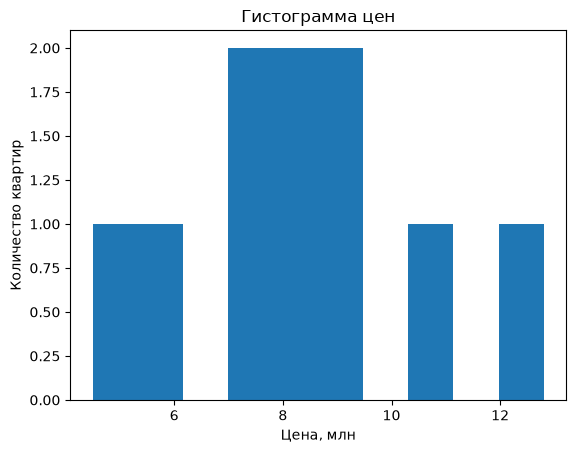

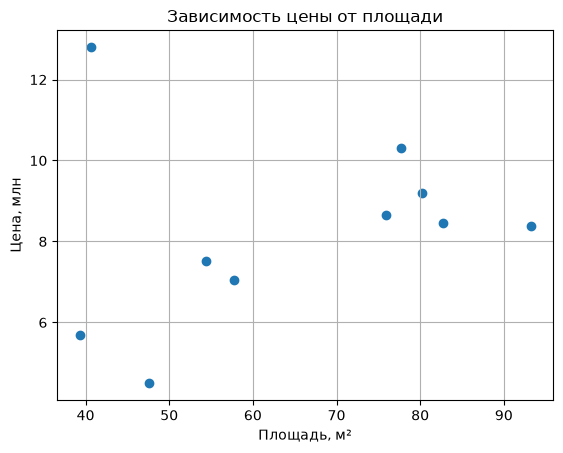

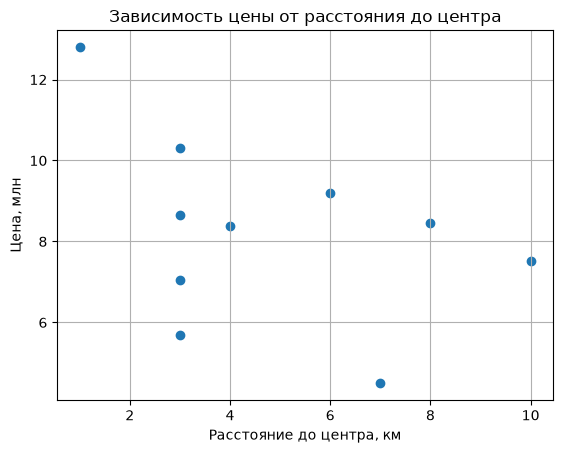

In [9]:
print(f"1) Количество квартир: {len(Y)}")
print(f"2) Количество признаков: {X.shape[1]}")

print("3) Тип данных каждого признака:")
for name, col in zip(names, columns):
    print(f"   {name} - {col.dtype}")

print(f"4) Найдено дубликатов: {n_dup} (удалены)")

print("5) Минимальные и максимальные значения:")
for i in range(len(names)):
    print(f"   {names[i]}: min = {X[:, i].min()}, max = {X[:, i].max()}")
print(f"   price (млн): min = {Y.min()}, max = {Y.max()}")

print(f"6) Среднее значение цены: {Y.mean():.3f} млн")
print(f"   Медианное значение цены: {np.median(Y):.3f} млн")

# а) Гистограмма цен
plt.hist(Y)
plt.title("Гистограмма цен")
plt.xlabel("Цена, млн")
plt.ylabel("Количество квартир")
plt.show()

# б) Цена от площади
plt.scatter(X[:, 0], Y)
plt.title("Зависимость цены от площади")
plt.xlabel("Площадь, м²")
plt.ylabel("Цена, млн")
plt.grid()
plt.show()

# в) Цена от расстояния до центра
plt.scatter(X[:, 4], Y)
plt.title("Зависимость цены от расстояния до центра")
plt.xlabel("Расстояние до центра, км")
plt.ylabel("Цена, млн")
plt.grid()
plt.show()


**Вопросы**

1. **Есть ли признаки, явно связанные с ценой?** Явной сильной связи на графиках не видно. Ожидаемо цена растёт с площадью и падает с расстоянием до центра.
2. **Можно ли ожидать линейную зависимость между площадью и ценой?** В целом да, но на наших данных разброс большой, поэтому прямая опишет данные грубо.
3. **Какие признаки могут быть взаимозависимыми?** `area` и `rooms` (больше комнат - больше площадь), `floor` и `total_floor` (этаж не может быть больше числа этажей в здании)


## **Часть 1.** Линейная регрессия

### 1. Линейная регрессия

w = 0.0823 (млн за 1 м²)
b = 2.2523 (млн)
MAE для первых 10 квартир теста = 3.903 млн
MAE = 3.903, MSE = 26.091, RMSE = 5.108, R2 = -4.515


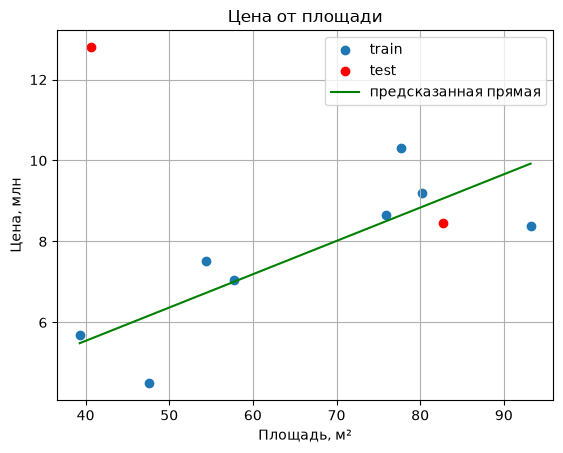

При +10 м² прогноз цены изменится на 0.823 млн


In [10]:
# 1. Модель на одном признаке - площади
area_train = X_train[:, 0].reshape(-1, 1)
area_test = X_test[:, 0].reshape(-1, 1)

model = LinearRegression()
model.fit(area_train, Y_train)

# 2. Коэффициенты
w = model.coef_[0]
b = model.intercept_
print(f"w = {w:.4f} (млн за 1 м²)")
print(f"b = {b:.4f} (млн)")

Y_pred = model.predict(area_test)

# 3. MAE для первых 10 квартир тестовой выборки
mae10 = mean_absolute_error(Y_test[:10], Y_pred[:10])
print(f"MAE для первых 10 квартир теста = {mae10:.3f} млн")

# 4. Метрики на всей тестовой выборке
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)
print(f"MAE = {mae:.3f}, MSE = {mse:.3f}, RMSE = {rmse:.3f}, R2 = {r2:.3f}")

# 5. График
x_line = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)

plt.scatter(area_train, Y_train, label="train")
plt.scatter(area_test, Y_test, color="red", label="test")
plt.plot(x_line, w * x_line + b, color="green", label="предсказанная прямая")
plt.title("Цена от площади")
plt.xlabel("Площадь, м²")
plt.ylabel("Цена, млн")
plt.legend()
plt.grid()
plt.show()

# 6. Что будет, если площадь увеличить на 10 м²
print(f"При +10 м² прогноз цены изменится на {10 * w:.3f} млн")


### 2. Множественная линейная регрессия

Коэффициенты модели:
   area: 0.1608
   rooms: -1.0812
   floor: -0.2003
   total_floor: 0.0781
   distance_center: 0.2308
   infrastructure: 1.4262
   condition: -1.3103
   furniture: 0.6594
   new_building: 2.3830
Свободный член b = -4.1450

5 главных признаков: ['new_building', 'infrastructure', 'condition', 'rooms', 'furniture']
Наибольший по модулю коэффициент у признака: new_building


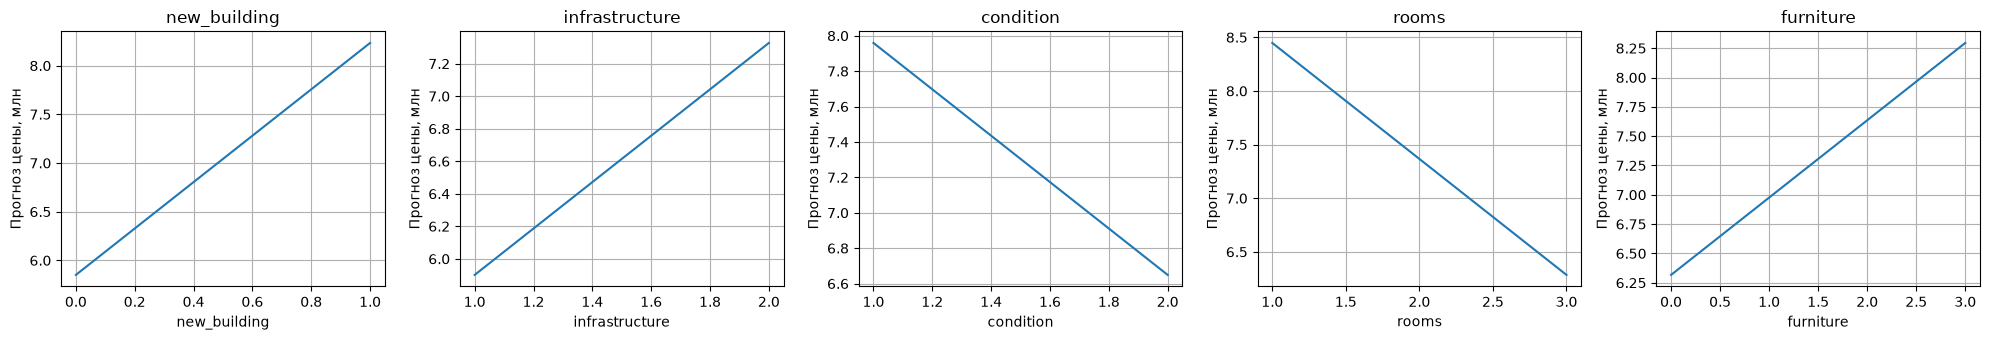

In [11]:
# 1. Обучаем модель по всем признакам
model2 = LinearRegression()
model2.fit(X_train, Y_train)

coefs = model2.coef_
print("Коэффициенты модели:")
for i in range(len(names)):
    print(f"   {names[i]}: {coefs[i]:.4f}")
print(f"Свободный член b = {model2.intercept_:.4f}")

# 2. Выбираем 5 главных признаков
top5 = np.argsort(np.abs(coefs))[::-1][:5]
print("\n5 главных признаков:", [names[i] for i in top5])
print(f"Наибольший по модулю коэффициент у признака: {names[top5[0]]}")


# Вспомогательная функция
def make_grid(i):
    grid = np.linspace(X[:, i].min(), X[:, i].max(), 100)
    X_grid = np.ones((100, 1)) * X.mean(axis=0)
    X_grid[:, i] = grid
    return grid, X_grid


# Зависимость предсказанной цены от каждого из 5 главных признаков
fig, ax = plt.subplots(1, 5, figsize=(20, 3.5))

for k in range(5):
    i = top5[k]
    grid, X_grid = make_grid(i)
    ax[k].plot(grid, model2.predict(X_grid))
    ax[k].set_title(names[i])
    ax[k].set_xlabel(names[i])
    ax[k].set_ylabel("Прогноз цены, млн")
    ax[k].grid()

plt.tight_layout()
plt.show()


**Вопросы**

1. **Какой признак имеет наибольший по модулю коэффициент?** `new_building` (≈ 2.38).
2. **Можно ли по коэффициенту определить, какой признак «важнее»?** Только если признаки в одинаковом масштабе. Здесь они в разных единицах, поэтому по обычным коэффициентам сравнивать нельзя - сначала нужно масштабирование.
3. **Что означает положительный коэффициент?** При росте признака прогноз цены растёт.
4. **Что означает отрицательный коэффициент?** При росте признака прогноз цены падает.

### 3. Немасштабированные признаки

In [12]:
# 1. Площадь, умноженная на 1 000 000
area_cm2_train = area_train * 1000000
area_cm2_test = area_test * 1000000

model_names = ["LinearRegression", "Ridge", "Lasso"]
models_area = [LinearRegression(), Ridge(alpha=1), Lasso(alpha=1)]
models_cm2 = [LinearRegression(), Ridge(alpha=1), Lasso(alpha=1)]

w_area_5 = [] 
w_cm2_5 = []

for i in range(3):
    models_area[i].fit(area_train, Y_train)
    models_cm2[i].fit(area_cm2_train, Y_train)

    pred_area = models_area[i].predict(area_test)
    pred_cm2 = models_cm2[i].predict(area_cm2_test)

    w1 = models_area[i].coef_[0]
    w2 = models_cm2[i].coef_[0]
    w_area_5.append(w1)
    w_cm2_5.append(w2)

    print(f"--- {model_names[i]} ---")
    print(f"w для area     = {w1:.6e}")
    print(f"w для area_cm2 = {w2:.6e}")
    print(f"w для area_cm2 * 1000000 = {w2 * 1000000:.6f}")
    print(f"R2 (area) = {r2_score(Y_test, pred_area):.4f}, R2 (area_cm2) = {r2_score(Y_test, pred_cm2):.4f}")
    print(f"Наибольшая разница в предсказаниях = {np.max(np.abs(pred_area - pred_cm2)):.6f} млн\n")


--- LinearRegression ---
w для area     = 8.229960e-02
w для area_cm2 = 8.229960e-08
w для area_cm2 * 1000000 = 0.082300
R2 (area) = -4.5154, R2 (area_cm2) = -4.5154
Наибольшая разница в предсказаниях = 0.000000 млн

--- Ridge ---
w для area     = 8.226573e-02
w для area_cm2 = 8.229960e-08
w для area_cm2 * 1000000 = 0.082300
R2 (area) = -4.5140, R2 (area_cm2) = -4.5154
Наибольшая разница в предсказаниях = 0.000849 млн

--- Lasso ---
w для area     = 7.900630e-02
w для area_cm2 = 8.229959e-08
w для area_cm2 * 1000000 = 0.082300
R2 (area) = -4.3837, R2 (area_cm2) = -4.5154
Наибольшая разница в предсказаниях = 0.082538 млн



**Вопросы**

1. **Изменился ли коэффициент?** Да. У `area_cm2` он в 1 000 000 раз меньше (≈ 8.2e-8 против 0.0823), а `b` не поменялся.
2. **Изменилось ли качество модели?** У LinearRegression нет: R² одинаковый.
3. **Изменились ли предсказания?** У LinearRegression нет (разница 0). У Ridge разница крошечная, а у Lasso заметная (≈ 0.08 млн).
4. **Почему коэффициент изменился, если физический смысл остался прежним?** Коэффициент показывает, на сколько меняется цена при увеличении признака на одну единицу. Единица стала в миллион раз меньше, значит и коэффициент в миллион раз меньше (м$^2$ = 1000000 см$^2$)


### 4. Масштабирование

In [13]:
# Масштабирование: отдельно для area и для area_cm2
scaler_area = StandardScaler()
area_train_s = scaler_area.fit_transform(area_train)
area_test_s = scaler_area.transform(area_test)

scaler_cm2 = StandardScaler()
area_cm2_train_s = scaler_cm2.fit_transform(area_cm2_train)
area_cm2_test_s = scaler_cm2.transform(area_cm2_test)

models_area_s = [LinearRegression(), Ridge(alpha=1), Lasso(alpha=1)]
models_cm2_s = [LinearRegression(), Ridge(alpha=1), Lasso(alpha=1)]

for i in range(3):
    models_area_s[i].fit(area_train_s, Y_train)
    models_cm2_s[i].fit(area_cm2_train_s, Y_train)

    pred_area = models_area_s[i].predict(area_test_s)
    pred_cm2 = models_cm2_s[i].predict(area_cm2_test_s)

    print(f"--- {model_names[i]} ---")
    print(f"БЕЗ масштабирования: w(area) = {w_area_5[i]:.6e}, w(area_cm2) = {w_cm2_5[i]:.6e}")
    print(f"С масштабированием: w(area) = {models_area_s[i].coef_[0]:.6f}, w(area_cm2) = {models_cm2_s[i].coef_[0]:.6f}")
    print(f"R2 (area) = {r2_score(Y_test, pred_area):.4f}, R2 (area_cm2) = {r2_score(Y_test, pred_cm2):.4f}\n")


--- LinearRegression ---
БЕЗ масштабирования: w(area) = 8.229960e-02, w(area_cm2) = 8.229960e-08
С масштабированием: w(area) = 1.434110, w(area_cm2) = 1.434110
R2 (area) = -4.5154, R2 (area_cm2) = -4.5154

--- Ridge ---
БЕЗ масштабирования: w(area) = 8.226573e-02, w(area_cm2) = 8.229960e-08
С масштабированием: w(area) = 1.274764, w(area_cm2) = 1.274764
R2 (area) = -4.1548, R2 (area_cm2) = -4.1548

--- Lasso ---
БЕЗ масштабирования: w(area) = 7.900630e-02, w(area_cm2) = 8.229959e-08
С масштабированием: w(area) = 0.434110, w(area_cm2) = 0.434110
R2 (area) = -2.5204, R2 (area_cm2) = -2.5204



**Вопросы**

1. **Изменилось ли качество модели?** У LinearRegression нет. У Ridge и Lasso изменилось.
2. **Изменились ли коэффициенты?** Да, например у LinearRegression с 0.082 до 1.43.
3. **Почему коэффициенты изменились?** Признак теперь измеряется в стандартных отклонениях. Коэффициент показывает, на сколько изменится цена при росте площади на одно стандартное отклонение (≈ 17 м²), поэтому 0.082 · 17 ≈ 1.43.
4. **Можно ли теперь сравнивать коэффициенты между собой более корректно?** Да: все признаки в одной шкале, и коэффициент `area` равен коэффициенту `area_cm2` (1.434 = 1.434).
5. **Почему стандартизация особенно важна для регуляризации?** Штраф считается от величины коэффициентов. Без масштабирования признак с большими числами имеет маленький коэффициент и почти не штрафуется, а признак с маленькими числами штрафуется сильно. Масштабирование делает штраф справедливым для всех признаков.


### 5. Исследование Ridge

alpha = 0.01: MAE = 6.112, RMSE = 8.556, R2 = -14.474
alpha = 0.1: MAE = 5.629, RMSE = 7.880, R2 = -12.126
alpha = 1: MAE = 3.928, RMSE = 5.520, R2 = -5.441
alpha = 10: MAE = 2.846, RMSE = 3.916, R2 = -2.241
alpha = 100: MAE = 2.888, RMSE = 3.667, R2 = -1.842
alpha = 1000: MAE = 2.951, RMSE = 3.672, R2 = -1.850


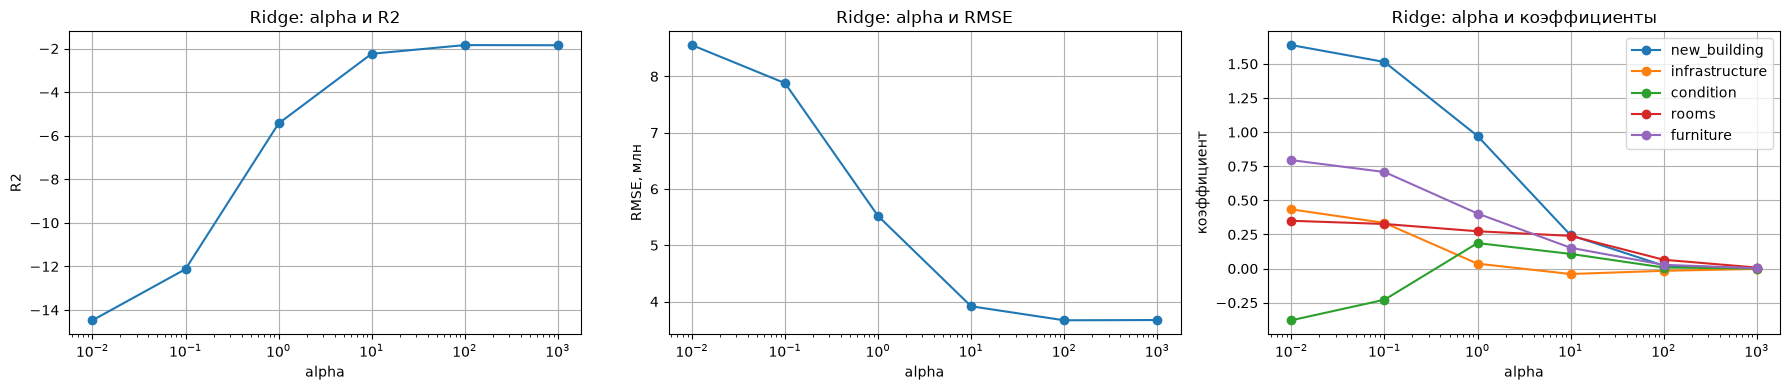

In [14]:
# 1. Масштабируем все признаки
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Значения alpha
alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge_mae = []
ridge_rmse = []
ridge_r2 = []
ridge_coefs = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_scaled, Y_train)
    pred = ridge.predict(X_test_scaled)

    mae = mean_absolute_error(Y_test, pred)
    rmse = np.sqrt(mean_squared_error(Y_test, pred))
    r2 = r2_score(Y_test, pred)

    ridge_mae.append(mae)
    ridge_rmse.append(rmse)
    ridge_r2.append(r2)
    ridge_coefs.append(ridge.coef_)

    print(f"alpha = {a}: MAE = {mae:.3f}, RMSE = {rmse:.3f}, R2 = {r2:.3f}")

ridge_coefs = np.array(ridge_coefs)   # строки - alpha, столбцы - признаки

# 4. Графики
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

ax[0].plot(alphas, ridge_r2, marker="o")
ax[0].set_xscale("log")
ax[0].set_title("Ridge: alpha и R2")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("R2")
ax[0].grid()

ax[1].plot(alphas, ridge_rmse, marker="o")
ax[1].set_xscale("log")
ax[1].set_title("Ridge: alpha и RMSE")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("RMSE, млн")
ax[1].grid()

for i in top5:
    ax[2].plot(alphas, ridge_coefs[:, i], marker="o", label=names[i])
ax[2].set_xscale("log")
ax[2].set_title("Ridge: alpha и коэффициенты")
ax[2].set_xlabel("alpha")
ax[2].set_ylabel("коэффициент")
ax[2].legend()
ax[2].grid()

plt.tight_layout()
plt.show()


**Вопросы**

1. **Что происходит с коэффициентами при увеличении alpha?** Уменьшаются по модулю (например, у `area` с ≈ 2.07 при alpha = 0.01 до ≈ 0.01 при alpha = 1000).
2. **Стремятся ли коэффициенты к нулю?** Да, но Ridge никогда не делает их ровно нулём.
3. **Что происходит с качеством модели?** До alpha ≈ 100 качество улучшается (RMSE падает с 8.6 до 3.7), дальше почти не меняется. R² при этом всё равно отрицательный из-за крошечной тестовой выборки (2 квартиры).
4. **Почему слишком большое alpha может ухудшить предсказание?** Все коэффициенты почти нули, модель перестаёт учитывать признаки и предсказывает примерно среднюю цену (недообучение).
5. **Как регуляризация влияет на сложность модели?** Чем больше alpha, тем проще модель: она меньше подстраивается под шум и реже переобучается.


### 6. Исследование Lasso

alpha = 0.01: MAE = 6.601, RMSE = 9.109, R2 = -16.539
alpha = 0.1: MAE = 4.075, RMSE = 5.760, R2 = -6.013
alpha = 1: MAE = 3.062, RMSE = 4.081, R2 = -2.520
alpha = 10: MAE = 2.960, RMSE = 3.674, R2 = -1.853
alpha = 100: MAE = 2.960, RMSE = 3.674, R2 = -1.853
alpha = 1000: MAE = 2.960, RMSE = 3.674, R2 = -1.853


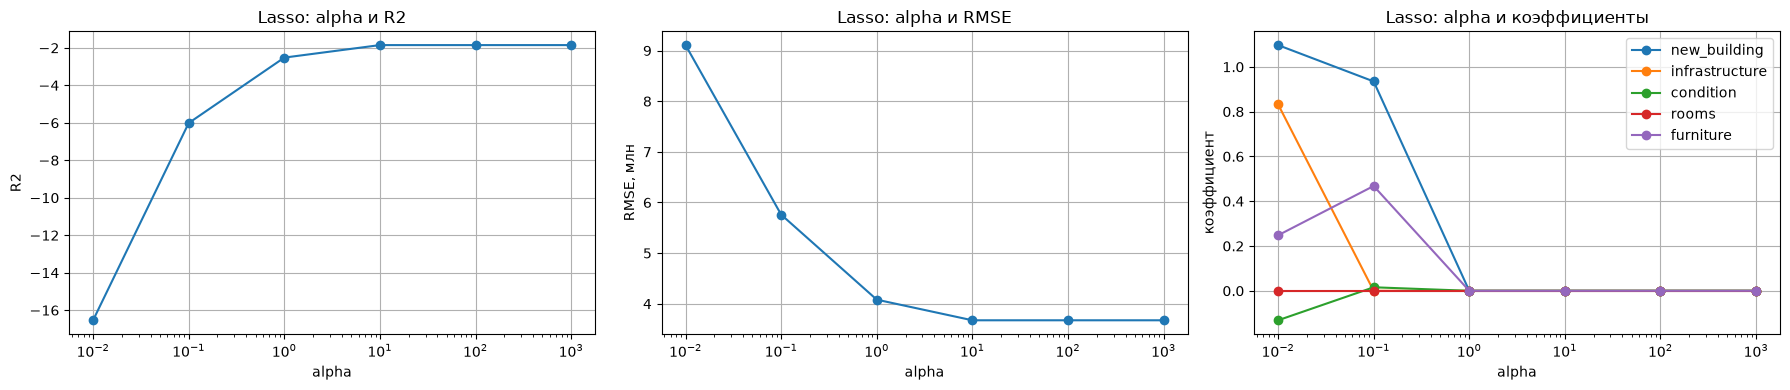

In [15]:
lasso_mae = []
lasso_rmse = []
lasso_r2 = []
lasso_coefs = []

for a in alphas:
    lasso = Lasso(alpha=a, max_iter=10000)
    lasso.fit(X_train_scaled, Y_train)
    pred = lasso.predict(X_test_scaled)

    mae = mean_absolute_error(Y_test, pred)
    rmse = np.sqrt(mean_squared_error(Y_test, pred))
    r2 = r2_score(Y_test, pred)

    lasso_mae.append(mae)
    lasso_rmse.append(rmse)
    lasso_r2.append(r2)
    lasso_coefs.append(lasso.coef_)

    print(f"alpha = {a}: MAE = {mae:.3f}, RMSE = {rmse:.3f}, R2 = {r2:.3f}")

lasso_coefs = np.array(lasso_coefs)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

ax[0].plot(alphas, lasso_r2, marker="o")
ax[0].set_xscale("log")
ax[0].set_title("Lasso: alpha и R2")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("R2")
ax[0].grid()

ax[1].plot(alphas, lasso_rmse, marker="o")
ax[1].set_xscale("log")
ax[1].set_title("Lasso: alpha и RMSE")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("RMSE, млн")
ax[1].grid()

for i in top5:
    ax[2].plot(alphas, lasso_coefs[:, i], marker="o", label=names[i])
ax[2].set_xscale("log")
ax[2].set_title("Lasso: alpha и коэффициенты")
ax[2].set_xlabel("alpha")
ax[2].set_ylabel("коэффициент")
ax[2].legend()
ax[2].grid()

plt.tight_layout()
plt.show()


**Вопросы** (те же, что для Ridge)

1. **Что происходит с коэффициентами при увеличении alpha?** Уменьшаются, и быстрее, чем у Ridge: уже при alpha = 1 все признаки, кроме `area`, обнулились.
2. **Стремятся ли коэффициенты к нулю?** Да, и Lasso делает их *точно* равными нулю. При alpha = 10 и больше обнулились все 9 коэффициентов.
3. **Что происходит с качеством модели?** Сначала улучшается (RMSE с 9.1 до 3.7), а при alpha ≥ 10 перестаёт меняться, потому что модель превращается в константу.
4. **Почему слишком большое alpha может ухудшить предсказание?** Все признаки отбрасываются, и модель всегда выдаёт одну и ту же цену (среднюю по train).
5. **Как регуляризация влияет на сложность модели?** Чем больше alpha, тем меньше признаков используется - модель проще.


### 7. Ridge vs Lasso

In [16]:
# 1. Таблица Ridge vs Lasso
print(f"{'alpha':<8}{'Ridge R2':>11}{'Lasso R2':>11}{'Ridge RMSE':>13}{'Lasso RMSE':>13}")
for i in range(len(alphas)):
    print(f"{alphas[i]:<8}{ridge_r2[i]:>11.3f}{lasso_r2[i]:>11.3f}{ridge_rmse[i]:>13.3f}{lasso_rmse[i]:>13.3f}")

# 2. Таблица коэффициентов 
lin_scaled = LinearRegression()
lin_scaled.fit(X_train_scaled, Y_train)

ridge_c = ridge_coefs[2]
lasso_c = lasso_coefs[2]

print(f"\n{'Признак':<17}{'Linear':>10}{'Ridge':>10}{'Lasso':>10}")
for i in range(len(names)):
    print(f"{names[i]:<17}{lin_scaled.coef_[i]:>10.3f}{ridge_c[i]:>10.3f}{lasso_c[i]:>10.3f}")


alpha      Ridge R2   Lasso R2   Ridge RMSE   Lasso RMSE
0.01        -14.474    -16.539        8.556        9.109
0.1         -12.126     -6.013        7.880        5.760
1            -5.441     -2.520        5.520        4.081
10           -2.241     -1.853        3.916        3.674
100          -1.842     -1.853        3.667        3.674
1000         -1.850     -1.853        3.672        3.674

Признак              Linear     Ridge     Lasso
area                  2.085     1.320     0.434
rooms                 0.354     0.274     0.000
floor                -0.848    -0.059     0.000
total_floor           0.160    -0.156     0.000
distance_center       0.079    -0.084     0.000
infrastructure        0.447     0.036     0.000
condition            -0.399     0.187     0.000
furniture             0.806     0.404     0.000
new_building          1.653     0.972     0.000


**Вывод.** Ridge уменьшает все коэффициенты, но не обнуляет. Lasso обнуляет лишние признаки: при alpha = 1 у него остался только `area`.


### 8. Удаление признаков

Порядок удаления признаков: ['rooms', 'floor', 'total_floor', 'distance_center', 'condition', 'infrastructure', 'furniture', 'new_building', 'area']

Признаков         R2     RMSE      MAE   Удалён последним
9            -14.801    8.646    6.176   -
8            -15.079    8.721    6.230   rooms
7             -3.480    4.604    3.587   floor
6             -6.308    5.880    4.191   total_floor
5             -5.546    5.565    4.019   distance_center
4             -5.593    5.585    4.047   condition
3             -6.646    6.014    4.255   infrastructure
2             -7.022    6.160    4.450   furniture
1             -4.515    5.108    3.903   new_building


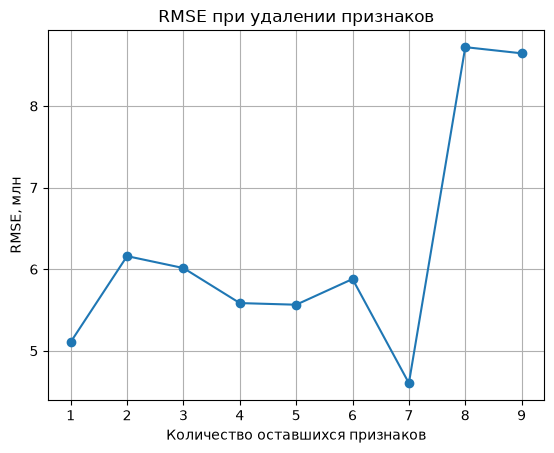

In [17]:
order = np.argsort(np.abs(lasso_c))

print("Порядок удаления признаков:", [names[i] for i in order])
print()

print(f"{'Признаков':<11}{'R2':>9}{'RMSE':>9}{'MAE':>9}   Удалён последним")

num_left = []
rem_r2 = []
rem_rmse = []
rem_mae = []

for k in range(len(names)):
    keep = order[k:]

    m = LinearRegression()
    m.fit(X_train_scaled[:, keep], Y_train)
    pred = m.predict(X_test_scaled[:, keep])

    r2 = r2_score(Y_test, pred)
    rmse = np.sqrt(mean_squared_error(Y_test, pred))
    mae = mean_absolute_error(Y_test, pred)

    num_left.append(len(keep))
    rem_r2.append(r2)
    rem_rmse.append(rmse)
    rem_mae.append(mae)

    last = names[order[k - 1]] if k > 0 else "-"
    print(f"{len(keep):<11}{r2:>9.3f}{rmse:>9.3f}{mae:>9.3f}   {last}")

plt.plot(num_left, rem_rmse, marker="o")
plt.title("RMSE при удалении признаков")
plt.xlabel("Количество оставшихся признаков")
plt.ylabel("RMSE, млн")
plt.grid()
plt.show()


**Главный вопрос: какие признаки действительно необходимы модели?**

Lasso оставляет ненулевым только `area` (при alpha = 1) и последним при удалении остаётся тоже `area`, следующими по важности идут `new_building` и `furniture`. По таблице лучшее качество (RMSE ≈ 4.6) у модели из 7 признаков, то есть после удаления `rooms` и `floor`, а модель только на `area` (RMSE ≈ 5.1) лучше полной модели из 9 признаков (RMSE ≈ 8.6). Значит, часть признаков модели не нужна и даже мешает.

*Но тестовая выборка из 2 квартир даёт очень шумные метрики, поэтому на этих данных вывод ненадёжный. На большем количестве квартир код даст более честный результат.*


## **Часть 2.** Логистическая регрессия

### 1. Исходные данные

In [18]:
median_price = np.median(Y)
expensive_class = np.where(Y > median_price, 1, 0)

print(f"Медианная цена: {median_price:.3f} млн")
for i in range(len(Y)):
    print(f"Квартира {i + 1}: цена = {Y[i]:.3f} млн, expensive_class = {expensive_class[i]}")


Медианная цена: 8.419 млн
Квартира 1: цена = 5.699 млн, expensive_class = 0
Квартира 2: цена = 12.800 млн, expensive_class = 1
Квартира 3: цена = 4.500 млн, expensive_class = 0
Квартира 4: цена = 7.506 млн, expensive_class = 0
Квартира 5: цена = 7.052 млн, expensive_class = 0
Квартира 6: цена = 8.653 млн, expensive_class = 1
Квартира 7: цена = 10.320 млн, expensive_class = 1
Квартира 8: цена = 9.200 млн, expensive_class = 1
Квартира 9: цена = 8.450 млн, expensive_class = 1
Квартира 10: цена = 8.388 млн, expensive_class = 0


### 2. Обучение логистической регрессии

In [19]:
# 1. Делим данные
X_train, X_test, C_train, C_test = train_test_split(
    X,
    expensive_class,
    test_size = 0.2,
    random_state = 42
)

# 2. Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Обучение
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, C_train)

# 4. Предсказание и вероятности
C_pred = log_model.predict(X_test_scaled)
C_prob = log_model.predict_proba(X_test_scaled)

print("Предсказанные классы:", C_pred)
print("Фактические классы:  ", C_test)
print(f"Accuracy = {accuracy_score(C_test, C_pred):.3f}")


Предсказанные классы: [1 0]
Фактические классы:   [1 1]
Accuracy = 0.500


### 3. Анализ вероятности

Квартира    Факт. класс  Предск. класс   P(класс 0)   P(класс 1)
1                     1              1        0.286        0.714
2                     1              0        0.783        0.217


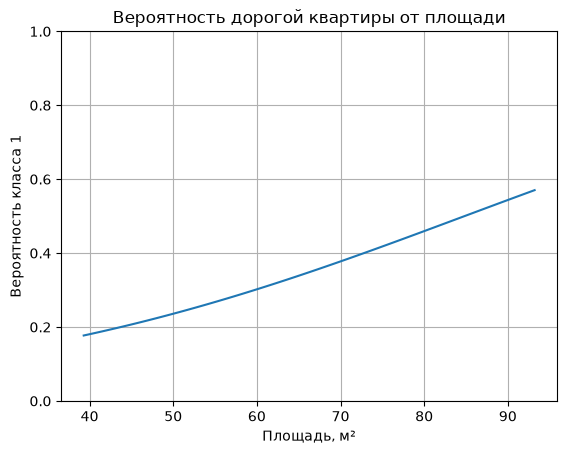

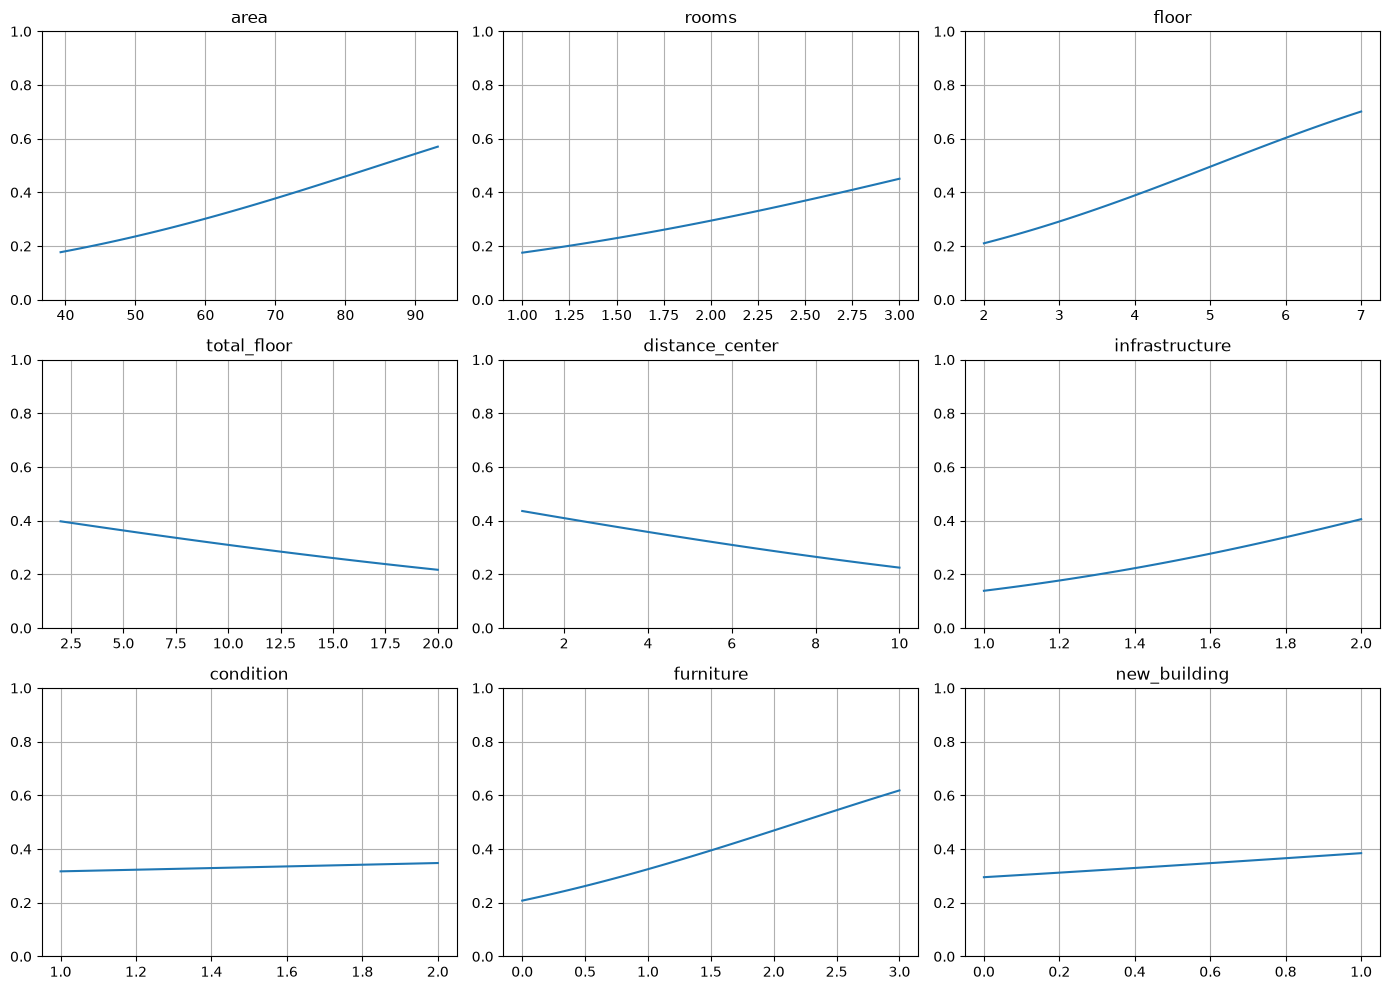

In [20]:
# 1. Таблица для тестовых квартир
print(f"{'Квартира':<10}{'Факт. класс':>13}{'Предск. класс':>15}{'P(класс 0)':>13}{'P(класс 1)':>13}")
for i in range(len(C_test)):
    print(f"{i + 1:<10}{C_test[i]:>13}{C_pred[i]:>15}{C_prob[i, 0]:>13.3f}{C_prob[i, 1]:>13.3f}")

# 2. График
grid, X_grid = make_grid(0)
prob = log_model.predict_proba(scaler.transform(X_grid))[:, 1]

plt.plot(grid, prob)
plt.title("Вероятность дорогой квартиры от площади")
plt.xlabel("Площадь, м²")
plt.ylabel("Вероятность класса 1")
plt.ylim(0, 1)
plt.grid()
plt.show()

fig, ax = plt.subplots(3, 3, figsize=(14, 10))
ax = ax.ravel()

for i in range(len(names)):
    grid, X_grid = make_grid(i)
    prob = log_model.predict_proba(scaler.transform(X_grid))[:, 1]
    ax[i].plot(grid, prob)
    ax[i].set_title(names[i])
    ax[i].set_ylim(0, 1)
    ax[i].grid()

plt.tight_layout()
plt.show()


**Вопросы**

1. **Как изменение площади влияет на вероятность?** С ростом площади вероятность дорогой квартиры плавно растёт (на графике примерно с 0.18 до 0.57).
2. **Всегда ли увеличение площади увеличивает вероятность?** Направление зависит от знака коэффициента у признака. Для площади в нашей модели - растёт, а у `total_floor` и `distance_center` вероятность с ростом признака падает. И рост не линейный: кривая имеет S-образную форму и замедляется возле 0 и 1.
3. **Что произойдёт около границы между классами?** Около вероятности 0.5 модель сомневается, и небольшое изменение признаков может поменять предсказанный класс. Здесь же вероятность меняется быстрее всего.
4. **Почему модель выдаёт вероятность, а не просто 0 или 1?** Вероятность показывает уверенность модели (0.51 и 0.99 - большая разница), и по ней можно выбирать порог под задачу.


### 4. Исследование порога

In [22]:
treshold = [0.3, 0.5, 0.7]

prob1 = C_prob[:, 1]

print(f"{'Порог':<8}{'Accuracy':>10}{'Precision':>11}{'Recall':>9}")
for t in treshold:
    pred_t = np.where(prob1 >= t, 1, 0)

    acc = accuracy_score(C_test, pred_t)
    prec = precision_score(C_test, pred_t, zero_division=0)
    rec = recall_score(C_test, pred_t, zero_division=0)

    print(f"{t:<8}{acc:>10.3f}{prec:>11.3f}{rec:>9.3f}")


Порог     Accuracy  Precision   Recall
0.3          0.500      1.000    0.500
0.5          0.500      1.000    0.500
0.7          0.500      1.000    0.500


**Вопрос: что меняется в работе классификатора при изменении порога с 0.5 на 0.3 и 0.7?**

- Порог **0.3**: квартиру легче признать дорогой, поэтому класс 1 предсказывается чаще. Recall обычно растёт (находим больше дорогих), precision обычно падает (больше ложных «дорогих»).
- Порог **0.7**: класс 1 только при высокой уверенности. Precision обычно растёт, recall падает.

## **ИТОГОВЫЙ ЭКСПЕРИМЕНТ**

Исследуем признак: area


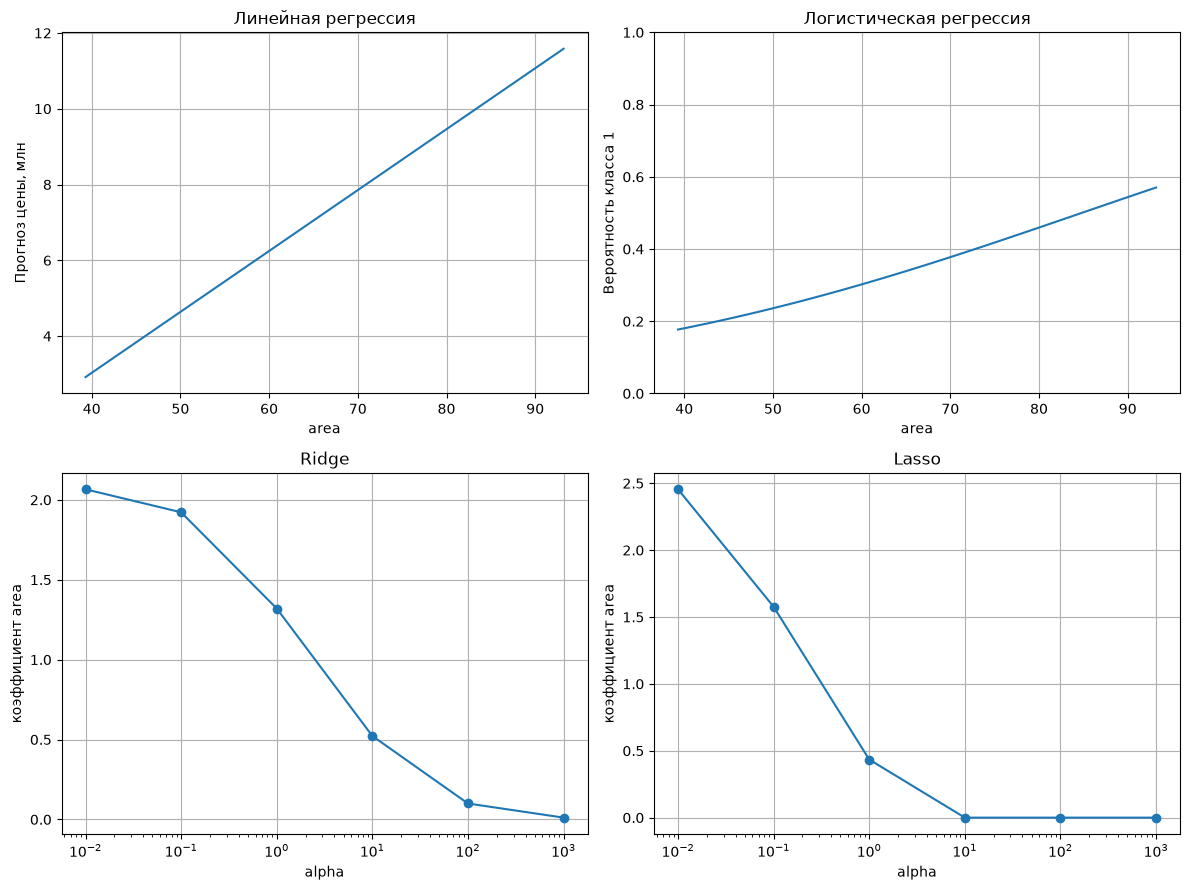

In [23]:
f = 0
print(f"Исследуем признак: {names[f]}")

grid, X_grid = make_grid(f)

fig, ax = plt.subplots(2, 2, figsize=(12, 9))

# 1. Линейная регрессия:
ax[0, 0].plot(grid, model2.predict(X_grid))
ax[0, 0].set_title("Линейная регрессия")
ax[0, 0].set_xlabel(names[f])
ax[0, 0].set_ylabel("Прогноз цены, млн")
ax[0, 0].grid()

# 2. Логистическая регрессия
prob = log_model.predict_proba(scaler.transform(X_grid))[:, 1]
ax[0, 1].plot(grid, prob)
ax[0, 1].set_title("Логистическая регрессия")
ax[0, 1].set_xlabel(names[f])
ax[0, 1].set_ylabel("Вероятность класса 1")
ax[0, 1].set_ylim(0, 1)
ax[0, 1].grid()

# 3. Ridge
ax[1, 0].plot(alphas, ridge_coefs[:, f], marker="o")
ax[1, 0].set_xscale("log")
ax[1, 0].set_title("Ridge")
ax[1, 0].set_xlabel("alpha")
ax[1, 0].set_ylabel(f"коэффициент {names[f]}")
ax[1, 0].grid()

# 4. Lasso
ax[1, 1].plot(alphas, lasso_coefs[:, f], marker="o")
ax[1, 1].set_xscale("log")
ax[1, 1].set_title("Lasso")
ax[1, 1].set_xlabel("alpha")
ax[1, 1].set_ylabel(f"коэффициент {names[f]}")
ax[1, 1].grid()

plt.tight_layout()
plt.show()


**Выводы по выбранному признаку (`area`)**

- **Линейная регрессия:** прогноз цены растёт по прямой с ростом площади.
- **Логистическая регрессия:** вероятность дорогой квартиры растёт плавно по S-образной кривой.
- **Ridge:** коэффициент при площади постепенно уменьшается с ростом alpha (с ≈ 2.07 до ≈ 0), но не равен нулю.
- **Lasso:** коэффициент при площади уменьшается быстрее и при alpha ≥ 10 становится ровно нулём.